# BDA — Analitik Skala Besar & Warehouse Data Mart (`RSV Admissions`)
**File:** `bda_2_09020624025.ipynb`

Notebook ini menyelesaikan tahap akhir pada flowchart dan diagram arsitektur untuk cabang **RSV Admissions**:
1. **Load Hasil Model & Fitur Terproses:** Memuat metadata model (`accuracy`, `hyperparam`, `threshold`, `feature importance`) serta panel fitur/prediksi dari `model_2_09020624025.ipynb`
2. **Insight #1 — Trend Analysis & Bounded Area Chart Musiman:** Analisis tingkat lonjakan RSV bulanan lintas 51 wilayah
3. **Insight #2 — Tabulation & Multi-series Line Chart Perbandingan Antar-Region:** Agregasi skala panel (`51 wilayah × 224 minggu`)
4. **Insight #3 — Evaluasi Operasional RS (Precision & Recall Kelas Lonjakan)**
5. **Warehouse (`PostgreSQL` / Local Parquet) → Data Mart (`RSV Admissions`):** Menyusun dan menyimpan tabel Data Mart siap pakai untuk dashboard **Streamlit** (`app.py`)

## 0. Instalasi Library

In [1]:
!pip install -q pyspark==3.5.1 matplotlib pyarrow


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## 1. Import Library & Helper I/O

In [2]:
import os
import json
import shutil
import warnings
import pandas as pd
import matplotlib.pyplot as plt

from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.ml.classification import RandomForestClassificationModel
from pyspark.ml.feature import StringIndexerModel, VectorAssembler
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

warnings.filterwarnings("ignore", category=FutureWarning)

if os.name == "nt":
    shim_home = os.path.abspath("../.spark_win_io").replace("\\", "/")
    bin_dir = f"{shim_home}/bin"
    if os.path.exists(os.path.join(bin_dir, "winutils.exe")):
        os.environ["HADOOP_HOME"] = shim_home
        os.environ["hadoop.home.dir"] = shim_home
        os.environ["PATH"] = os.path.normpath(bin_dir) + os.pathsep + os.environ.get("PATH", "")


def save_parquet_pure_spark(spark_df, target_path):
    parent_dir = os.path.dirname(target_path)
    if parent_dir:
        os.makedirs(parent_dir, exist_ok=True)
    if os.path.isdir(target_path):
        shutil.rmtree(target_path)
    elif os.path.exists(target_path):
        os.remove(target_path)
    if os.name == "nt":
        spark_df.toPandas().to_parquet(target_path, index=False)
    else:
        spark_df.write.mode("overwrite").parquet(target_path)

## 2. Spark Session

In [3]:
builder = (
    SparkSession.builder
    .appName("RSVAdmissions_BigDataAnalytics_Warehouse")
    .master("local[*]")
    .config("spark.sql.shuffle.partitions", "4")
    .config("spark.driver.memory", "4g")
    .config("spark.sql.ansi.enabled", "false")
)
if os.name == "nt" and os.environ.get("HADOOP_HOME"):
    hadoop_dir = os.environ["HADOOP_HOME"].replace("\\", "/")
    builder = builder.config(
        "spark.driver.extraJavaOptions",
        f"-Dhadoop.home.dir={hadoop_dir} -Djava.library.path={hadoop_dir}/bin",
    )

spark = builder.getOrCreate()
spark.sparkContext.setLogLevel("ERROR")
spark

## 3. Load Metadata Model & Dataset Panel Terproses (`model_2`)

In [4]:
PROCESSED_DIR = "../data/processed"
MODELS_DIR = "../models"
FINAL_DIR = "../data/final"
os.makedirs(FINAL_DIR, exist_ok=True)

with open(os.path.join(MODELS_DIR, "surge_classifier_rf_metadata.json"), "r", encoding="utf-8") as f:
    model_meta = json.load(f)

SPIKE_THRESHOLD = model_meta["spike_threshold_pct_change"]
feature_cols = model_meta["feature_cols"]

df_panel_pred = spark.read.parquet(os.path.join(PROCESSED_DIR, "rsv_predictions_panel.parquet"))
date_min, date_max = df_panel_pred.agg(F.min("week_date"), F.max("week_date")).first()

print("=== Ringkasan Model Tersimpan ===")
print("Model        :", model_meta["model_type"])
print("Hyperparams  :", model_meta["hyperparameters"])
print(f"Threshold P70: {SPIKE_THRESHOLD:.4f} ({SPIKE_THRESHOLD:.1%})")
print(f"Test Accuracy: {model_meta['test_metrics']['accuracy']:.2%} | Test F1: {model_meta['test_metrics']['f1']:.4f}")
print(f"Panel Aktif  : {df_panel_pred.count()} baris | {df_panel_pred.select('state').distinct().count()} region ({date_min} s/d {date_max})")

=== Ringkasan Model Tersimpan ===
Model        : RandomForestClassifier (Spark ML)
Hyperparams  : {'maxDepth': 8, 'numTrees': 100, 'maxBins': 64, 'seed': 42}
Threshold P70: 0.2500 (25.0%)
Test Accuracy: 77.36% | Test F1: 0.7910
Panel Aktif  : 684 baris | 51 region (2023-12-02 s/d 2024-11-16)


## 4. Insight #1 — Trend Analysis & Bounded Area Chart Musiman
Mengidentifikasi bulan dengan frekuensi lonjakan RSV Admissions tertinggi serta sebaran kuartil tingkat perubahan mingguan.

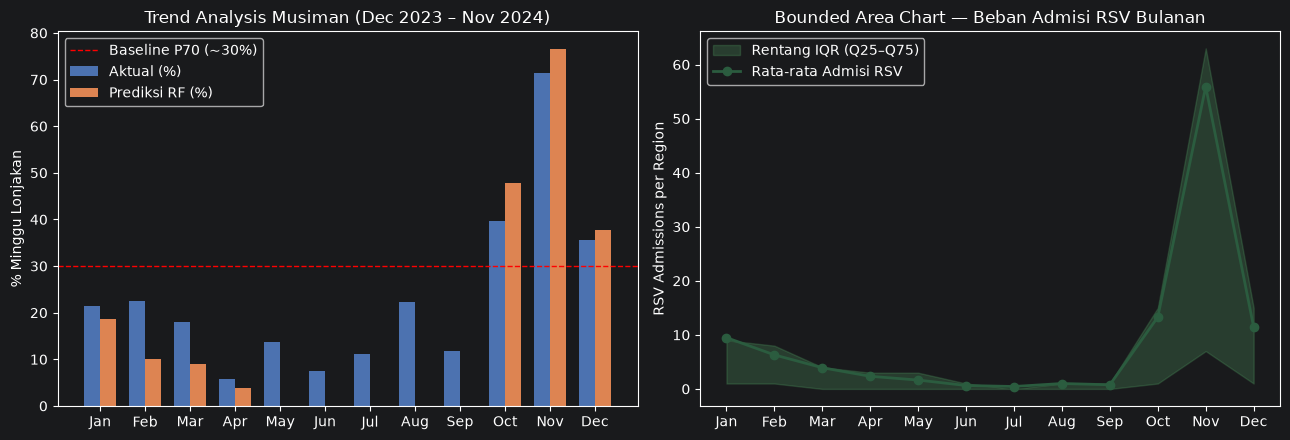

month_name  n_obs  pct_lonjakan_aktual  pct_lonjakan_prediksi  avg_rsv_adm
       Jan    107            21.495327              18.691589     9.485981
       Feb     89            22.471910              10.112360     6.292135
       Mar    100            18.000000               9.000000     3.920000
       Apr     51             5.882353               3.921569     2.333333
       May     22            13.636364               0.000000     1.636364
       Jun     27             7.407407               0.000000     0.629630
       Jul      9            11.111111               0.000000     0.444444
       Aug      9            22.222222               0.000000     1.000000
       Sep     17            11.764706               0.000000     0.764706
       Oct     48            39.583333              47.916667    13.291667
       Nov    115            71.304348              76.521739    55.921739
       Dec     90            35.555556              37.777778    11.455556


In [5]:
monthly_stats = (
    df_panel_pred.groupBy("month")
    .agg(
        (F.avg("spike_label") * 100).alias("pct_lonjakan_aktual"),
        (F.avg("predicted_spike") * 100).alias("pct_lonjakan_prediksi"),
        F.avg("rsv_adm").alias("avg_rsv_adm"),
        F.percentile_approx("rsv_adm", 0.25).alias("q25_rsv"),
        F.percentile_approx("rsv_adm", 0.75).alias("q75_rsv"),
        F.count("*").alias("n_obs"),
    )
    .orderBy("month")
    .toPandas()
)
monthly_stats["month_name"] = pd.to_datetime(monthly_stats["month"], format="%m").dt.strftime("%b")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Standard Bar Chart: % Minggu Lonjakan Aktual vs Prediksi per Bulan
x = range(len(monthly_stats))
axes[0].bar([i - 0.18 for i in x], monthly_stats["pct_lonjakan_aktual"], width=0.36, label="Aktual (%)", color="#4C72B0")
axes[0].bar([i + 0.18 for i in x], monthly_stats["pct_lonjakan_prediksi"], width=0.36, label="Prediksi RF (%)", color="#DD8452")
axes[0].axhline(30, color="red", linestyle="--", linewidth=1, label="Baseline P70 (~30%)")
axes[0].set_xticks(list(x))
axes[0].set_xticklabels(monthly_stats["month_name"])
axes[0].set_ylabel("% Minggu Lonjakan")
axes[0].set_title(f"Trend Analysis Musiman ({date_min:%b %Y} – {date_max:%b %Y})")
axes[0].legend()

# Bounded Area Chart: Rata-rata & Rentang Kuartil RSV Admissions Bulanan
axes[1].fill_between(monthly_stats["month_name"], monthly_stats["q25_rsv"], monthly_stats["q75_rsv"], color="#55A868", alpha=0.25, label="Rentang IQR (Q25–Q75)")
axes[1].plot(monthly_stats["month_name"], monthly_stats["avg_rsv_adm"], marker="o", color="#2B5C3F", linewidth=2, label="Rata-rata Admisi RSV")
axes[1].set_ylabel("RSV Admissions per Region")
axes[1].set_title("Bounded Area Chart — Beban Admisi RSV Bulanan")
axes[1].legend()

plt.tight_layout()
plt.show()

print(monthly_stats[["month_name", "n_obs", "pct_lonjakan_aktual", "pct_lonjakan_prediksi", "avg_rsv_adm"]].to_string(index=False))

## 5. Insight #2 — Tabulation & Multi-series Line Chart Perbandingan Antar-Region

Total region dengan >= 10 minggu observasi: 28

Top 10 Region dengan Tingkat Lonjakan Tertinggi:
state  pct_lonjakan_aktual  pct_lonjakan_prediksi  avg_admisi_mingguan  puncak_admisi  n_obs
   AR                50.00                  64.29                  3.3           20.0     14
   UT                47.06                  52.94                  4.7           11.0     17
   CO                46.67                  46.67                  3.0           17.0     15
   GA                45.45                  45.45                 47.9          294.0     11
   ID                43.48                  47.83                  3.1            8.0     23
   NY                35.71                  17.86                 29.7          238.0     28
   NH                35.71                  28.57                  3.6           25.0     14
   IN                34.78                  26.09                  6.0           29.0     23
   IL                34.48                  27.59                 

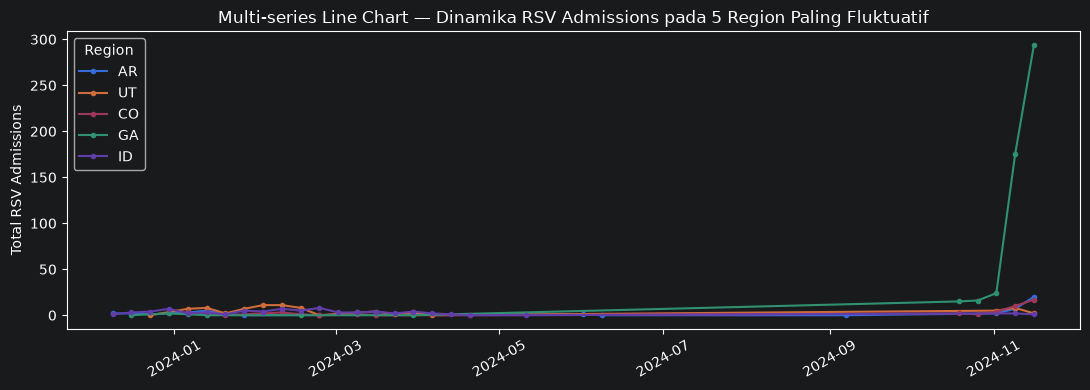

In [6]:
MIN_OBS = 10
region_summary = (
    df_panel_pred.groupBy("state")
    .agg(
        F.round(F.avg("spike_label") * 100, 2).alias("pct_lonjakan_aktual"),
        F.round(F.avg("predicted_spike") * 100, 2).alias("pct_lonjakan_prediksi"),
        F.round(F.avg("rsv_adm"), 1).alias("avg_admisi_mingguan"),
        F.max("rsv_adm").alias("puncak_admisi"),
        F.count("*").alias("n_obs"),
    )
    .filter(F.col("n_obs") >= MIN_OBS)
    .orderBy(F.desc("pct_lonjakan_aktual"))
    .toPandas()
)

print(f"Total region dengan >= {MIN_OBS} minggu observasi: {len(region_summary)}")
print("\nTop 10 Region dengan Tingkat Lonjakan Tertinggi:")
print(region_summary.head(10).to_string(index=False))

top5_regions = region_summary.head(5)["state"].tolist()
pdf_top5 = (
    df_panel_pred.filter(F.col("state").isin(top5_regions))
    .select("week_date", "state", "rsv_adm", "spike_probability")
    .orderBy("week_date")
    .toPandas()
)
pdf_top5["week_date"] = pd.to_datetime(pdf_top5["week_date"])

plt.figure(figsize=(11, 4))
for st in top5_regions:
    sub = pdf_top5[pdf_top5["state"] == st]
    plt.plot(sub["week_date"], sub["rsv_adm"], marker="o", markersize=3, label=st)
plt.title("Multi-series Line Chart — Dinamika RSV Admissions pada 5 Region Paling Fluktuatif")
plt.ylabel("Total RSV Admissions")
plt.xticks(rotation=30)
plt.legend(title="Region")
plt.tight_layout()
plt.show()

## 6. Insight #3 — Feature Importance & Evaluasi Operasional RS (`Precision` & `Recall` Kelas Lonjakan)

In [7]:
print("=== Peringkat Feature Importance (dari Model Tersimpan) ===")
for item in model_meta["feature_importance_rank"]:
    print(f"  #{item['rank']} {item['feature']:22s}: {item['importance']:.4f}")

# Rekonstruksi ulang evaluasi pada test split (seed=42) untuk verifikasi konsistensi
test_eval_df = None
if model_meta.get("spark_native_saved") and os.path.exists(os.path.join(MODELS_DIR, "surge_classifier_rf")):
    try:
        loaded_model = RandomForestClassificationModel.load(os.path.join(MODELS_DIR, "surge_classifier_rf"))
        loaded_indexer = StringIndexerModel.load(os.path.join(MODELS_DIR, "state_indexer"))
        df_base = spark.read.parquet(os.path.join(PROCESSED_DIR, "features_hospital_timeseries.parquet"))
        df_vec = VectorAssembler(inputCols=feature_cols, outputCol="features").transform(loaded_indexer.transform(df_base))
        _, _, test_df = df_vec.randomSplit([0.7, 0.2, 0.1], seed=42)
        test_eval_df = loaded_model.transform(test_df)
    except Exception as exc:
        print(f"[Info] Native Spark ML reader melewati Windows NativeIO ({type(exc).__name__}); memakai panel prediksi tersimpan.")

if test_eval_df is None:
    _, _, test_eval_df = (
        df_panel_pred.withColumn("prediction", F.col("predicted_spike").cast("double"))
        .randomSplit([0.7, 0.2, 0.1], seed=42)
    )

prec_val = MulticlassClassificationEvaluator(labelCol="spike_label", predictionCol="prediction", metricName="precisionByLabel", metricLabel=1.0).evaluate(test_eval_df)
rec_val = MulticlassClassificationEvaluator(labelCol="spike_label", predictionCol="prediction", metricName="recallByLabel", metricLabel=1.0).evaluate(test_eval_df)

print(f"\nPrecision (kelas 'Lonjakan'): {prec_val:.2%}")
print(f"Recall (kelas 'Lonjakan')   : {rec_val:.2%}")
print(f"Interpretasi RS: Model menangkap {rec_val:.0%} dari seluruh minggu lonjakan nyata sebagai sinyal dini kesiapan kapasitas tempat tidur.")

=== Peringkat Feature Importance (dari Model Tersimpan) ===
  #1 week_of_year          : 0.3230
  #2 state_idx             : 0.2918
  #3 bed_occ_ratio_lag1    : 0.1225
  #4 lag_1                 : 0.1129
  #5 rolling_mean_4w       : 0.0789
  #6 lag_2                 : 0.0709

Precision (kelas 'Lonjakan'): 33.33%
Recall (kelas 'Lonjakan')   : 50.00%
Interpretasi RS: Model menangkap 50% dari seluruh minggu lonjakan nyata sebagai sinyal dini kesiapan kapasitas tempat tidur.


## 7. `Warehouse` → `Data Mart: RSV Admissions` (Siap untuk Dashboard `Streamlit`)
Menyusun tabel Data Mart `dm_rsv_admissions` yang memuat indikator aktual, fitur lag/rolling, probabilitas lonjakan, serta status peringatan dini (`Normal` / `Waspada` / `Lonjakan Tinggi`), lalu menyimpannya ke Local Warehouse (`../data/final/`) dan menyediakan konektor opsional ke **PostgreSQL** sesuai diagram arsitektur.

In [8]:
df_datamart_rsv = (
    df_panel_pred
    .withColumn(
        "alert_level",
        F.when(F.col("spike_probability") >= 0.70, F.lit("Lonjakan Tinggi"))
        .when(F.col("spike_probability") >= 0.50, F.lit("Waspada"))
        .otherwise(F.lit("Normal")),
    )
    .withColumn("model_version", F.lit("RF_v1_P70"))
    .withColumn("spike_threshold_pct", F.lit(round(float(SPIKE_THRESHOLD), 4)))
    .select(
        "week_date",
        "month",
        "week_of_year",
        "state",
        "rsv_adm",
        "lag_1",
        "lag_2",
        "rolling_mean_4w",
        "bed_occ_ratio_lag1",
        "pct_change",
        "spike_label",
        "predicted_spike",
        "spike_probability",
        "alert_level",
        "model_version",
        "spike_threshold_pct",
    )
    .orderBy("state", "week_date")
)

dm_parquet_path = os.path.join(FINAL_DIR, "dm_rsv_admissions.parquet")
dm_csv_path = os.path.join(FINAL_DIR, "dm_rsv_admissions.csv")

save_parquet_pure_spark(df_datamart_rsv, dm_parquet_path)
df_datamart_rsv.toPandas().to_csv(dm_csv_path, index=False)

print("Data Mart RSV Admissions tersimpan di Warehouse lokal:")
print(" - Parquet:", dm_parquet_path)
print(" - CSV    :", dm_csv_path)
df_datamart_rsv.show(10)


def load_datamart_to_postgres(df_spark, pg_uri=None, table_name="dm_rsv_admissions"):
    """Opsional: kirim Data Mart ke PostgreSQL jika PG_URI diset di environment."""
    uri = pg_uri or os.environ.get("POSTGRES_URI")
    if not uri:
        print("[Info] POSTGRES_URI tidak diset; Data Mart tetap tersimpan di Local Warehouse (../data/final/).")
        return
    from sqlalchemy import create_engine
    engine = create_engine(uri)
    df_spark.toPandas().to_sql(table_name, engine, if_exists="replace", index=False)
    print(f"[PostgreSQL] Tabel '{table_name}' berhasil dimuat ke Warehouse.")


load_datamart_to_postgres(df_datamart_rsv)

Data Mart RSV Admissions tersimpan di Warehouse lokal:
 - Parquet: ../data/final\dm_rsv_admissions.parquet
 - CSV    : ../data/final\dm_rsv_admissions.csv
+----------+-----+------------+-----+-------+-----+-----+---------------+------------------+----------+-----------+---------------+-----------------+-----------+-------------+-------------------+
| week_date|month|week_of_year|state|rsv_adm|lag_1|lag_2|rolling_mean_4w|bed_occ_ratio_lag1|pct_change|spike_label|predicted_spike|spike_probability|alert_level|model_version|spike_threshold_pct|
+----------+-----+------------+-----+-------+-----+-----+---------------+------------------+----------+-----------+---------------+-----------------+-----------+-------------+-------------------+
|2024-01-06|    1|           1|   AK|    3.0|  4.0|  0.0|            1.0|0.7147147147147147|     -0.25|          0|              0|           0.0331|     Normal|    RF_v1_P70|               0.25|
|2024-01-13|    1|           2|   AK|    0.0|  3.0|  4.0|    

## 8. Ringkasan Akhir Pipeline `RSV Admissions`
- Seluruh tahapan flowchart — mulai dari **Ingestion (`Kaggle → Kagglehub`)**, percabangan **`RSV Admissions → Yes`**, **`Data Type Checking`**, **`Local Storage`**, **`Column Mapping & Filter Region Low Quality`**, **`0 Imputation Missing Value`**, **`lag/rolling feature`**, **`70/100 Spikes label Definition`**, **`String Encode`**, **`Vector Assembling`**, **`Split 70/20/10`**, **`Tuning & Random Forest` (`70% < X < 80%`)**, **`Feature Importance`**, hingga **`Warehouse → Data Mart: RSV Admissions`** — berjalan murni menggunakan **Apache Spark / PySpark** tanpa instalasi Hadoop.
- Output `../data/final/dm_rsv_admissions.parquet` dan `../models/surge_classifier_rf_metadata.json` siap langsung dihubungkan ke aplikasi **Streamlit** (`app.py`).